# California Housing Price Prediction

## 1. Project Overview

The objective of this project is to predict median
house values using the California Housing dataset.

This project implements and compares three regression
algorithms:

1. Ordinary Least Squares (OLS) Regression
2. Ridge Regression (L2 Regularization)
3. Lasso Regression (L1 Regularization)

## 2. Project Objectives

- Perform exploratory data analysis.
- Handle missing values.
- Perform feature engineering.
- Analyze multicollinearity.
- Apply feature scaling and encoding.
- Optimize hyperparameters using GridSearchCV.
- Evaluate models using RMSE, MAE and R².
- Perform residual error analysis.

##  Importing Required Libraries

In [149]:
# 1. Data Handling
import numpy as np
import pandas as pd

# 2. Data Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# 3. Data Preprocessing
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PolynomialFeatures
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# 4. Model Selection
from sklearn.model_selection import train_test_split, GridSearchCV

# 5. Regression Models
from sklearn.linear_model import LinearRegression, Ridge, Lasso

# 6. Model Evaluation
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# 7. Warnings
import warnings
warnings.filterwarnings('ignore')

print("All libraries imported successfully!")

All libraries imported successfully!


In [150]:
data=pd.read_csv("California_Housing_Dataset.csv")
df=pd.DataFrame(data)
df

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY
...,...,...,...,...,...,...,...,...,...,...
20635,-121.09,39.48,25.0,1665.0,374.0,845.0,330.0,1.5603,78100.0,INLAND
20636,-121.21,39.49,18.0,697.0,150.0,356.0,114.0,2.5568,77100.0,INLAND
20637,-121.22,39.43,17.0,2254.0,485.0,1007.0,433.0,1.7000,92300.0,INLAND
20638,-121.32,39.43,18.0,1860.0,409.0,741.0,349.0,1.8672,84700.0,INLAND


In [151]:
# Display first 5 rows
df.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [152]:
# Display last 5 rows
df.tail()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
20635,-121.09,39.48,25.0,1665.0,374.0,845.0,330.0,1.5603,78100.0,INLAND
20636,-121.21,39.49,18.0,697.0,150.0,356.0,114.0,2.5568,77100.0,INLAND
20637,-121.22,39.43,17.0,2254.0,485.0,1007.0,433.0,1.7000,92300.0,INLAND
20638,-121.32,39.43,18.0,1860.0,409.0,741.0,349.0,1.8672,84700.0,INLAND
20639,-121.24,39.37,16.0,2785.0,616.0,1387.0,530.0,2.3886,89400.0,INLAND


In [153]:
print("Number of rows and columns:", df.shape)

Number of rows and columns: (20640, 10)


In [154]:
print("Column Names:")
print(df.columns)

Column Names:
Index(['longitude', 'latitude', 'housing_median_age', 'total_rooms',
       'total_bedrooms', 'population', 'households', 'median_income',
       'median_house_value', 'ocean_proximity'],
      dtype='str')


In [155]:
#Dataset information check
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  str    
dtypes: float64(9), str(1)
memory usage: 1.6 MB


In [156]:
#Statistical summary
df.describe()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


In [157]:
# Check missing values in each column
print(df.isnull().sum())

longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64


In [158]:
missing_percentage = (df.isnull().sum() / len(df)) * 100
print(missing_percentage)

longitude             0.000000
latitude              0.000000
housing_median_age    0.000000
total_rooms           0.000000
total_bedrooms        1.002907
population            0.000000
households            0.000000
median_income         0.000000
median_house_value    0.000000
ocean_proximity       0.000000
dtype: float64


In [159]:
print("Total duplicate rows:", df.duplicated().sum())

Total duplicate rows: 0


In [160]:
print(df.dtypes)

longitude             float64
latitude              float64
housing_median_age    float64
total_rooms           float64
total_bedrooms        float64
population            float64
households            float64
median_income         float64
median_house_value    float64
ocean_proximity           str
dtype: object


In [161]:
print("Unique ocean proximity categories:")
print(df["ocean_proximity"].unique())

Unique ocean proximity categories:
<StringArray>
['NEAR BAY', '<1H OCEAN', 'INLAND', 'NEAR OCEAN', 'ISLAND']
Length: 5, dtype: str


##  Exploratory Data Analysis (EDA)

Exploratory Data Analysis (EDA) is performed to understand the dataset's structure, identify data quality issues, and discover patterns and relationships among the variables before building machine learning models.

In this phase, we will:

- Analyze the dataset structure, dimensions, and data types.
- Identify missing values and duplicate records.
- Examine categorical and numerical features.
- Understand the distribution of the target variable.
- Visualize relationships between numerical features using correlation analysis.
- Identify potential multicollinearity among input features.

**Objective:** To gain meaningful insights into the dataset and determine the preprocessing steps required before model training.

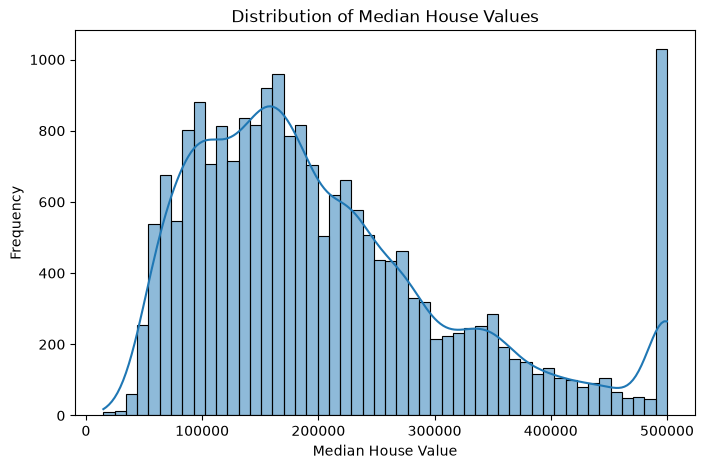

In [162]:
plt.figure(figsize=(8, 5))
sns.histplot(df["median_house_value"], bins=50, kde=True)
plt.title("Distribution of Median House Values")
plt.xlabel("Median House Value")
plt.ylabel("Frequency")
plt.show()

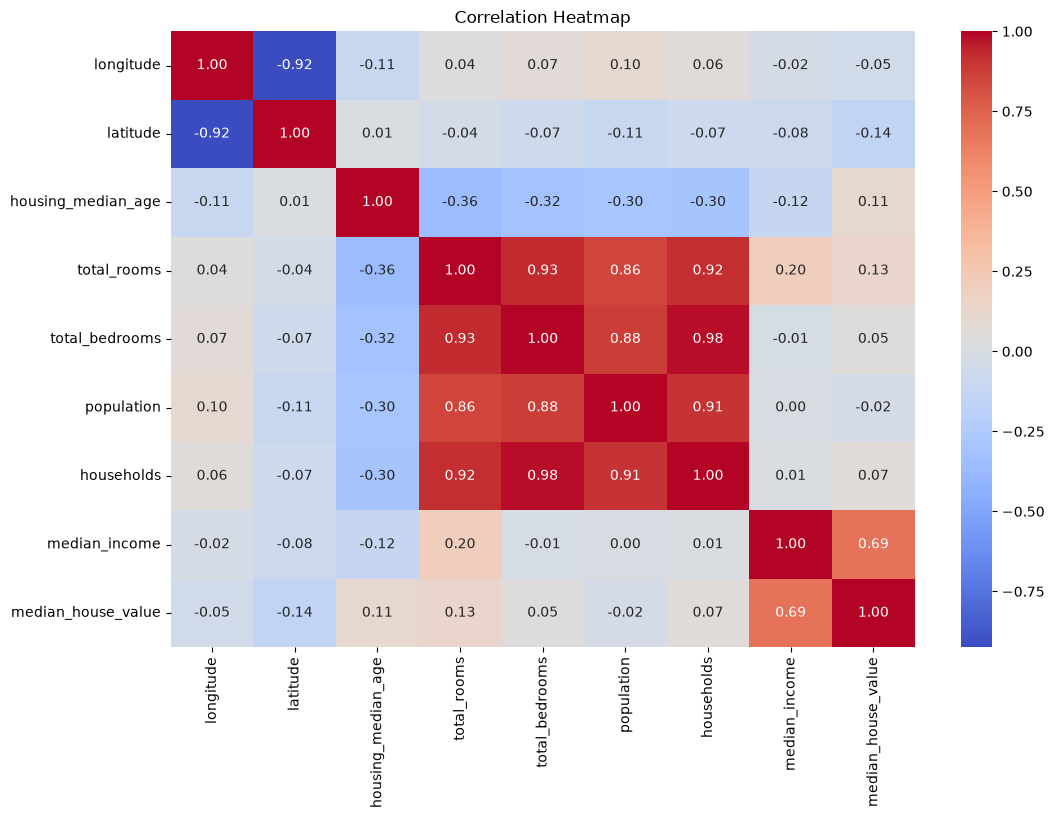

In [163]:
plt.figure(figsize=(12, 8))
correlation_matrix = df.select_dtypes(include=np.number).corr()
sns.heatmap(correlation_matrix,annot=True,cmap="coolwarm",fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

##  Data Cleaning and Feature Engineering

In this phase, the dataset will be prepared for machine learning by identifying and handling data quality issues.

The following operations will be performed:

- Handle missing values using median imputation for numerical features.
- Encode categorical variables into numerical representations.
- Create interaction features to capture relationships between input variables.
- Analyze multicollinearity among numerical features.
- Prepare the dataset for model training and evaluation.

**Objective:** To transform the raw dataset into a suitable format for regression models while maintaining data quality and preventing data leakage.

In [164]:
# Separate input features and target variable

X = df.drop("median_house_value", axis=1)
y = df["median_house_value"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (20640, 9)
Target shape: (20640,)


In [165]:
# Identify numerical and categorical columns

numerical_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(exclude=np.number).columns.tolist()

print("Numerical Features:")
print(numerical_features)

print("\nCategorical Features:")
print(categorical_features)

Numerical Features:
['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income']

Categorical Features:
['ocean_proximity']


In [166]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.20,random_state=42)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (16512, 9)
Testing features: (4128, 9)
Training target: (16512,)
Testing target: (4128,)


##  Data Preprocessing

Data preprocessing is an essential step before training machine learning models. It transforms raw data into a suitable format for machine learning algorithms.

In this project, we will perform the following preprocessing operations:

- **Missing Value Imputation:** Replace missing numerical values using the median.
- **Feature Scaling:** Standardize numerical features using StandardScaler.
- **Categorical Encoding:** Convert categorical variables into numerical values using OneHotEncoder.

We will use ColumnTransformer and Pipeline to apply these transformations systematically and prevent data leakage during model training.

In [167]:
# Numerical preprocessing pipeline

numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

In [168]:
# Categorical preprocessing pipeline

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

In [169]:
# Combine numerical and categorical preprocessing

preprocessor = ColumnTransformer([
    ("num", numerical_pipeline, numerical_features),
    ("cat", categorical_pipeline, categorical_features)
])

##  Feature Engineering

Feature engineering is the process of creating new input features from existing variables to improve a machine learning model's ability to identify patterns.

In this project, interaction features will be created to capture relationships between selected numerical variables.

These additional features may help regression models understand relationships that individual features alone might not capture.

In [170]:
# Create interaction features

interaction_features = PolynomialFeatures(degree=2,interaction_only=True,include_bias=False)

In [171]:
interaction_columns = ["median_income","housing_median_age","total_rooms"]

In [172]:
# Numerical features not selected for interaction

remaining_numerical_features = [
    col for col in numerical_features
    if col not in interaction_columns
]

print("Remaining numerical features:")
print(remaining_numerical_features)

Remaining numerical features:
['longitude', 'latitude', 'total_bedrooms', 'population', 'households']


In [173]:
# Pipeline for interaction features

interaction_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("polynomial", PolynomialFeatures(degree=2,interaction_only=True,include_bias=False)),
    ("scaler", StandardScaler())
])

In [174]:
preprocessor = ColumnTransformer([
    ("num", numerical_pipeline, remaining_numerical_features),
    ("interaction", interaction_pipeline, interaction_columns),
    ("cat", categorical_pipeline, categorical_features)
])

##  Multicollinearity Analysis Using VIF

Multicollinearity occurs when two or more independent variables are highly correlated with each other.

It can make regression coefficients unstable and difficult to interpret.

To identify multicollinearity, we will use the Variance Inflation Factor (VIF).

Features with high VIF values will be examined, and regularization techniques such as Ridge and Lasso Regression will be used to reduce the impact of multicollinearity.

In [175]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
import statsmodels.api as sm

In [176]:
X_vif = X_train[numerical_features].copy()
X_vif.head()


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income
14196,-117.03,32.71,33.0,3126.0,627.0,2300.0,623.0,3.2596
8267,-118.16,33.77,49.0,3382.0,787.0,1314.0,756.0,3.8125
17445,-120.48,34.66,4.0,1897.0,331.0,915.0,336.0,4.1563
14265,-117.11,32.69,36.0,1421.0,367.0,1418.0,355.0,1.9425
2271,-119.80,36.78,43.0,2382.0,431.0,874.0,380.0,3.5542


In [177]:
print("Shape:", X_vif.shape)

Shape: (16512, 8)


In [178]:
vif_imputer = SimpleImputer(strategy="median")
X_vif = pd.DataFrame(vif_imputer.fit_transform(X_vif),columns=numerical_features,index=X_train.index)

print("Missing values after imputation:")
print(X_vif.isnull().sum())

Missing values after imputation:
longitude             0
latitude              0
housing_median_age    0
total_rooms           0
total_bedrooms        0
population            0
households            0
median_income         0
dtype: int64


In [179]:
X_vif_constant = sm.add_constant(X_vif)
X_vif_constant.head()

,const,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income
14196,1.0,-117.03,32.71,33.0,3126.0,627.0,2300.0,623.0,3.2596
8267,1.0,-118.16,33.77,49.0,3382.0,787.0,1314.0,756.0,3.8125
17445,1.0,-120.48,34.66,4.0,1897.0,331.0,915.0,336.0,4.1563
14265,1.0,-117.11,32.69,36.0,1421.0,367.0,1418.0,355.0,1.9425
2271,1.0,-119.80,36.78,43.0,2382.0,431.0,874.0,380.0,3.5542


In [180]:
vif_data = pd.DataFrame()
vif_data["Feature"] = X_vif_constant.columns

vif_data["VIF"] = [
    variance_inflation_factor(X_vif_constant.values, i)
    for i in range(X_vif_constant.shape[1])
]

vif_data = vif_data[vif_data["Feature"] != "const"]
vif_data = vif_data.sort_values(by="VIF",ascending=False)
print(vif_data)

              Feature        VIF
5      total_bedrooms  36.307087
7          households  35.824564
4         total_rooms  12.821807
2            latitude   8.798267
1           longitude   8.681823
6          population   6.345431
8       median_income   1.740998
3  housing_median_age   1.257629


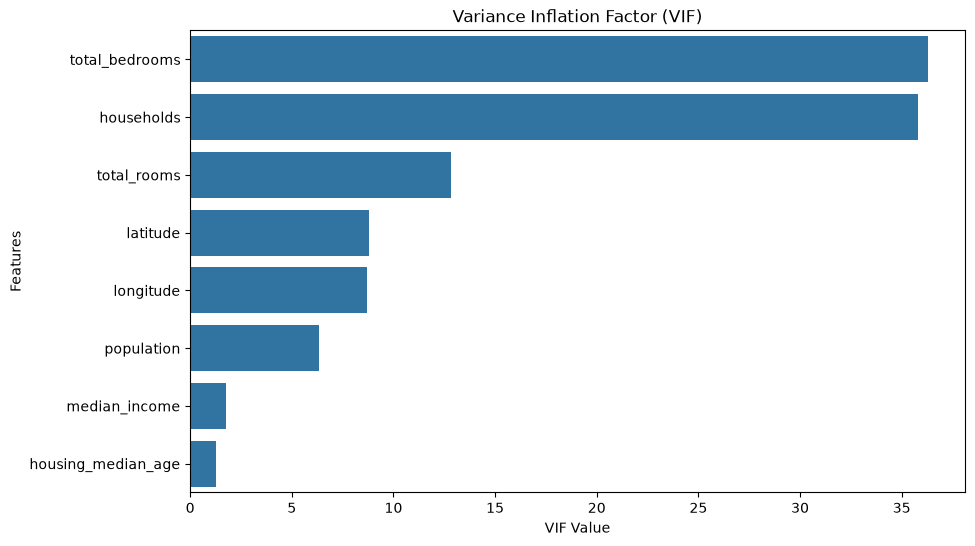

In [181]:
plt.figure(figsize=(10, 6))
sns.barplot(data=vif_data,x="VIF",y="Feature")
plt.title("Variance Inflation Factor (VIF)")
plt.xlabel("VIF Value")
plt.ylabel("Features")
plt.show()

### VIF Results Interpretation

The VIF analysis indicates potential multicollinearity among several numerical features.

- `total_bedrooms` has the highest VIF of 36.31.
- `households` has a VIF of 35.82.
- `total_rooms` has a VIF of 12.82.
- `latitude`, `longitude`, and `population` also show elevated VIF values.
- `median_income` and `housing_median_age` have relatively low VIF values.

These results suggest that some numerical features contain overlapping information. Instead of immediately removing these features, regularization techniques such as Ridge and Lasso Regression will be used to examine and manage multicollinearity.

##  Model Training

In this section, we will train and evaluate three regression models: Linear Regression, Ridge Regression, and Lasso Regression.

We will begin with Linear Regression as our baseline model. Ridge and Lasso Regression will then be used to examine the impact of regularization on model performance and multicollinearity.

In [182]:
linear_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LinearRegression())
])

In [183]:
linear_pipeline.fit(X_train, y_train)
print("Linear Regression model trained successfully!")

Linear Regression model trained successfully!


In [184]:
y_pred_linear = linear_pipeline.predict(X_test)
print("Predictions generated successfully!")
print("First 10 predictions:")
print(y_pred_linear[:10])

Predictions generated successfully!
First 10 predictions:
[ 64500.02687102 119879.50976366 246339.11076176 262859.86422181
 261387.28982718 122548.07688775 292263.81613852 230335.58804659
 248243.01408565 420552.27298943]


##  Model Evaluation

The trained Linear Regression model will be evaluated using three performance metrics:

- **RMSE (Root Mean Squared Error):** Measures the average prediction error, giving greater weight to larger errors.
- **MAE (Mean Absolute Error):** Measures the average absolute difference between actual and predicted house prices.
- **R² Score:** Measures how much variation in house prices is explained by the model.

In [185]:
# Calculate RMSE
rmse_linear = np.sqrt(mean_squared_error(y_test, y_pred_linear))
# Calculate MAE
mae_linear = mean_absolute_error(y_test, y_pred_linear)
# Calculate R2 Score
r2_linear = r2_score(y_test, y_pred_linear)

print("Linear Regression Model Evaluation")
print("-----------------------------------")
print("RMSE:", rmse_linear)
print("MAE:", mae_linear)
print("R2 Score:", r2_linear)

Linear Regression Model Evaluation
-----------------------------------
RMSE: 69709.74926701689
MAE: 49897.43148268212
R2 Score: 0.6291654572304815


### Linear Regression – Results and Interpretation

The Linear Regression model achieved an R² score of 0.6292, indicating that it explains approximately 62.92% of the variation in median house values.

The model obtained an RMSE of $69,709.75 and an MAE of $49,897.43.

These results establish a baseline for comparison with Ridge and Lasso Regression models. Further improvements will be explored using regularization techniques and hyperparameter tuning.

In [186]:
ridge_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", Ridge(alpha=1.0))
])

In [187]:
ridge_pipeline.fit(X_train, y_train)
print("Ridge Regression model trained successfully!")

Ridge Regression model trained successfully!


In [188]:
y_pred_ridge = ridge_pipeline.predict(X_test)
print("First 10 Ridge Predictions:")
print(y_pred_ridge[:10])

First 10 Ridge Predictions:
[ 64481.29222979 119942.33676899 246527.27441247 262887.15509371
 261389.69690797 122694.76893942 292218.63969007 230302.58342647
 248255.37204856 420533.33239033]


### Ridge Regression – Model Evaluation

Ridge Regression uses L2 regularization to reduce the magnitude of regression coefficients and help manage multicollinearity.

The model will be evaluated using RMSE, MAE, and R² Score to compare its performance with the baseline Linear Regression model.

In [189]:
# Calculate RMSE
rmse_ridge = np.sqrt(mean_squared_error(y_test, y_pred_ridge))
# Calculate MAE
mae_ridge = mean_absolute_error(y_test, y_pred_ridge)
# Calculate R2 Score
r2_ridge = r2_score(y_test, y_pred_ridge)

print("Ridge Regression Model Evaluation")
print("---------------------------------")
print("RMSE:", rmse_ridge)
print("MAE:", mae_ridge)
print("R2 Score:", r2_ridge)

Ridge Regression Model Evaluation
---------------------------------
RMSE: 69712.37315475155
MAE: 49901.682378024496
R2 Score: 0.6291375401448206


In [190]:
model_comparison = pd.DataFrame({"Model": ["Linear Regression", "Ridge Regression"],
    "RMSE": [rmse_linear, rmse_ridge],
    "MAE": [mae_linear, mae_ridge],
    "R2 Score": [r2_linear, r2_ridge]
})
model_comparison

,Model,RMSE,MAE,R2 Score
0,Linear Regression,69709.749267,49897.431483,0.629165
1,Ridge Regression,69712.373155,49901.682378,0.629138


### Lasso Regression

Lasso Regression is a linear regression technique that uses L1 regularization.

It penalizes large coefficients and can reduce some coefficients to exactly zero, helping with feature selection.

We will train the Lasso model and evaluate its performance using RMSE, MAE, and R² Score.

In [191]:
lasso_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", Lasso(alpha=1.0, max_iter=10000))
])

In [192]:
lasso_pipeline.fit(X_train, y_train)
print("Lasso Regression model trained successfully!")

Lasso Regression model trained successfully!


In [193]:
y_pred_lasso = lasso_pipeline.predict(X_test)
print("First 10 Lasso Predictions:")
print(y_pred_lasso[:10])

First 10 Lasso Predictions:
[ 64493.24076269 119889.83204595 246369.20240711 262869.07725834
 261377.33663159 122575.92485827 292258.84756083 230333.33499905
 248245.62507289 420539.92315023]


### Lasso Regression – Model Evaluation

The Lasso Regression model is evaluated using RMSE, MAE, and R² Score.

Its performance will be compared with Linear Regression and Ridge Regression to understand the effect of L1 regularization on prediction accuracy.

In [194]:
# Calculate RMSE
rmse_lasso = np.sqrt(mean_squared_error(y_test, y_pred_lasso))
# Calculate MAE
mae_lasso = mean_absolute_error(y_test, y_pred_lasso)
# Calculate R2 Score
r2_lasso = r2_score(y_test, y_pred_lasso)

print("Lasso Regression Model Evaluation")
print("---------------------------------")
print("RMSE:", rmse_lasso)
print("MAE:", mae_lasso)
print("R2 Score:", r2_lasso)

Lasso Regression Model Evaluation
---------------------------------
RMSE: 69710.16396884345
MAE: 49898.49044613481
R2 Score: 0.6291610450436269


In [195]:
model_comparison = pd.DataFrame({
    "Model": ["Linear Regression","Ridge Regression","Lasso Regression"],
    "RMSE": [rmse_linear,rmse_ridge,rmse_lasso],
    "MAE": [mae_linear,mae_ridge,mae_lasso],
    "R2 Score": [r2_linear,r2_ridge,r2_lasso]
})
model_comparison

,Model,RMSE,MAE,R2 Score
0,Linear Regression,69709.749267,49897.431483,0.629165
1,Ridge Regression,69712.373155,49901.682378,0.629138
2,Lasso Regression,69710.163969,49898.490446,0.629161


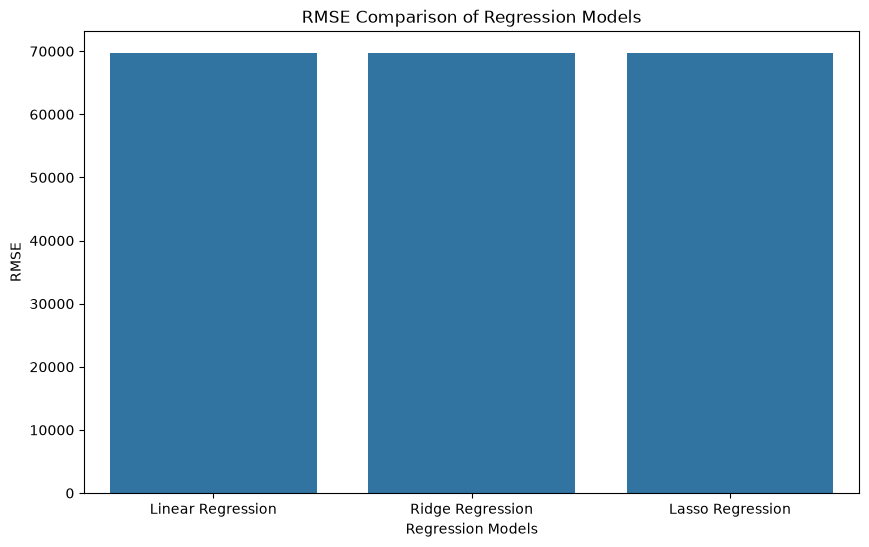

In [196]:
plt.figure(figsize=(10, 6))
sns.barplot(data=model_comparison,x="Model",y="RMSE")
plt.title("RMSE Comparison of Regression Models")
plt.xlabel("Regression Models")
plt.ylabel("RMSE")
plt.show()

### Comparison of Regression Models

The initial evaluation shows that Linear Regression, Ridge Regression, and Lasso Regression achieved very similar performance.

Linear Regression obtained the lowest RMSE of 69,709.75 and the highest R² score of 0.629165 among the three models.

Ridge and Lasso Regression showed nearly identical results to the baseline model with the initial alpha value of 1.0.

Further hyperparameter tuning using GridSearchCV will be performed to identify the optimal regularization strength for Ridge and Lasso Regression.

##  Hyperparameter Tuning Using GridSearchCV

GridSearchCV is used to identify the best hyperparameters for a machine learning model.

In this project, GridSearchCV will be applied to Ridge and Lasso Regression to find the optimal alpha value using 5-fold cross-validation.

The best alpha will be selected based on the lowest cross-validation RMSE.

In [197]:
alpha_values = [0.001, 0.01, 0.1, 1, 10, 100]
print("Alpha values:", alpha_values)

Alpha values: [0.001, 0.01, 0.1, 1, 10, 100]


In [198]:
ridge_tuning_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", Ridge())
])

In [199]:
ridge_param_grid = {
    "model__alpha": alpha_values
}

ridge_grid_search = GridSearchCV(
    estimator=ridge_tuning_pipeline,
    param_grid=ridge_param_grid,
    cv=5,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1
)

In [200]:
ridge_grid_search.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","Pipeline(step...l', Ridge())])"
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__alpha': [0.001, 0.01, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_root_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verbosity of informati

In [201]:
print("Best Alpha:", ridge_grid_search.best_params_["model__alpha"])
print("Best Cross-Validation RMSE:", -ridge_grid_search.best_score_)

Best Alpha: 1
Best Cross-Validation RMSE: 67937.10281397795


In [202]:
best_ridge_model = ridge_grid_search.best_estimator_
y_pred_ridge_tuned = best_ridge_model.predict(X_test)

In [203]:
ridge_tuned_rmse = np.sqrt(mean_squared_error(y_test, y_pred_ridge_tuned))
ridge_tuned_mae = mean_absolute_error(y_test, y_pred_ridge_tuned)
ridge_tuned_r2 = r2_score(y_test, y_pred_ridge_tuned)

print("Tuned Ridge Regression Results")
print("--------------------------------")
print("RMSE:", ridge_tuned_rmse)
print("MAE:", ridge_tuned_mae)
print("R2 Score:", ridge_tuned_r2)

Tuned Ridge Regression Results
--------------------------------
RMSE: 69712.37315475155
MAE: 49901.682378024496
R2 Score: 0.6291375401448206


In [204]:
print("Best Alpha:", ridge_grid_search.best_params_["model__alpha"])
print("Best CV RMSE:", -ridge_grid_search.best_score_)

Best Alpha: 1
Best CV RMSE: 67937.10281397795


In [205]:
lasso_param_grid = {"model__alpha": alpha_values}
print(lasso_param_grid)

{'model__alpha': [0.001, 0.01, 0.1, 1, 10, 100]}


In [206]:
lasso_tuning_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", Lasso(max_iter=20000))
])

In [207]:
lasso_grid_search = GridSearchCV(
    estimator=lasso_tuning_pipeline,
    param_grid=lasso_param_grid,
    cv=5,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1
)

In [208]:
lasso_grid_search.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...iter=20000))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__alpha': [0.001, 0.01, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_root_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verbosity of information

In [209]:
print("Best Alpha:", lasso_grid_search.best_params_["model__alpha"])
print("Best Cross-Validation RMSE:", -lasso_grid_search.best_score_)

Best Alpha: 0.1
Best Cross-Validation RMSE: 67937.9124478501


In [210]:
best_lasso_model = lasso_grid_search.best_estimator_
y_pred_lasso_tuned = best_lasso_model.predict(X_test)

In [211]:
lasso_tuned_rmse = np.sqrt(mean_squared_error(y_test, y_pred_lasso_tuned))
lasso_tuned_mae = mean_absolute_error(y_test, y_pred_lasso_tuned)
lasso_tuned_r2 = r2_score(y_test, y_pred_lasso_tuned)

print("Tuned Lasso Regression Results")
print("--------------------------------")
print("RMSE:", lasso_tuned_rmse)
print("MAE:", lasso_tuned_mae)
print("R2 Score:", lasso_tuned_r2)

Tuned Lasso Regression Results
--------------------------------
RMSE: 69709.78742279121
MAE: 49897.536346242916
R2 Score: 0.6291650512762743


##  Final Model Comparison

The initial regression models are compared with their tuned versions to evaluate the impact of hyperparameter optimization.

The comparison is based on RMSE, MAE, and R² score on the test dataset.

In [212]:
final_comparison = pd.DataFrame({
    "Model": ["Linear Regression","Ridge (Initial)","Ridge (Tuned)","Lasso (Initial)","Lasso (Tuned)"],
    "RMSE": [rmse_linear,rmse_ridge,ridge_tuned_rmse,rmse_lasso,lasso_tuned_rmse],
    "MAE": [mae_linear,mae_ridge,ridge_tuned_mae,mae_lasso,lasso_tuned_mae],
    "R2 Score": [r2_linear,r2_ridge,ridge_tuned_r2,r2_lasso,lasso_tuned_r2]
})
final_comparison

,Model,RMSE,MAE,R2 Score
0,Linear Regression,69709.749267,49897.431483,0.629165
1,Ridge (Initial),69712.373155,49901.682378,0.629138
2,Ridge (Tuned),69712.373155,49901.682378,0.629138
3,Lasso (Initial),69710.163969,49898.490446,0.629161
4,Lasso (Tuned),69709.787423,49897.536346,0.629165


In [213]:
best_model_row = final_comparison.loc[final_comparison["RMSE"].idxmin()]

print("Best Model:", best_model_row["Model"])
print("RMSE:", best_model_row["RMSE"])
print("MAE:", best_model_row["MAE"])
print("R2 Score:", best_model_row["R2 Score"])

Best Model: Linear Regression
RMSE: 69709.74926701689
MAE: 49897.43148268212
R2 Score: 0.6291654572304815


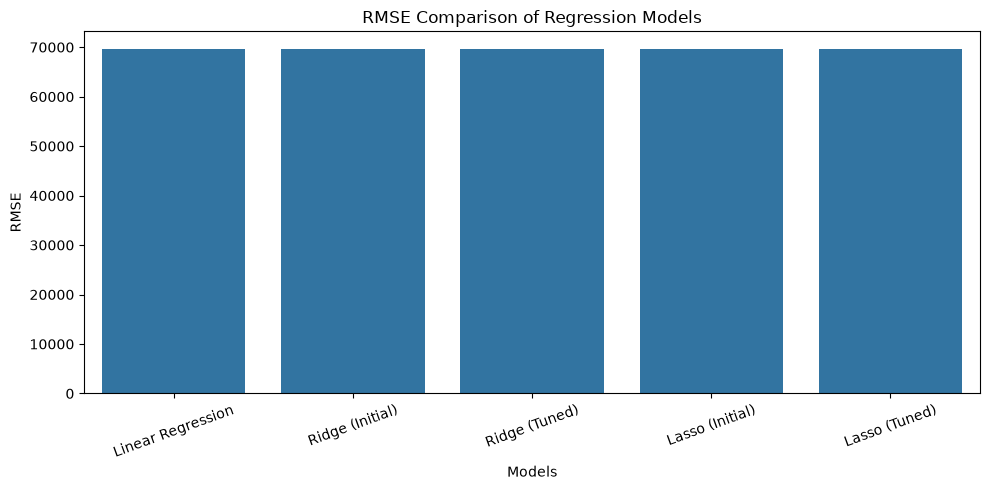

In [214]:
plt.figure(figsize=(10, 5))
sns.barplot(data=final_comparison,x="Model",y="RMSE")
plt.title("RMSE Comparison of Regression Models")
plt.xlabel("Models")
plt.ylabel("RMSE")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

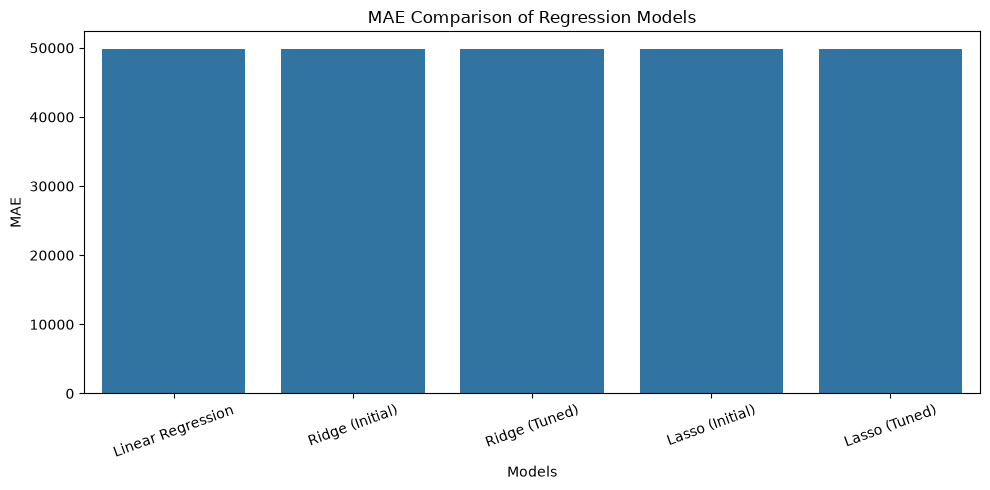

In [215]:
plt.figure(figsize=(10, 5))
sns.barplot(data=final_comparison,x="Model",y="MAE")
plt.title("MAE Comparison of Regression Models")
plt.xlabel("Models")
plt.ylabel("MAE")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

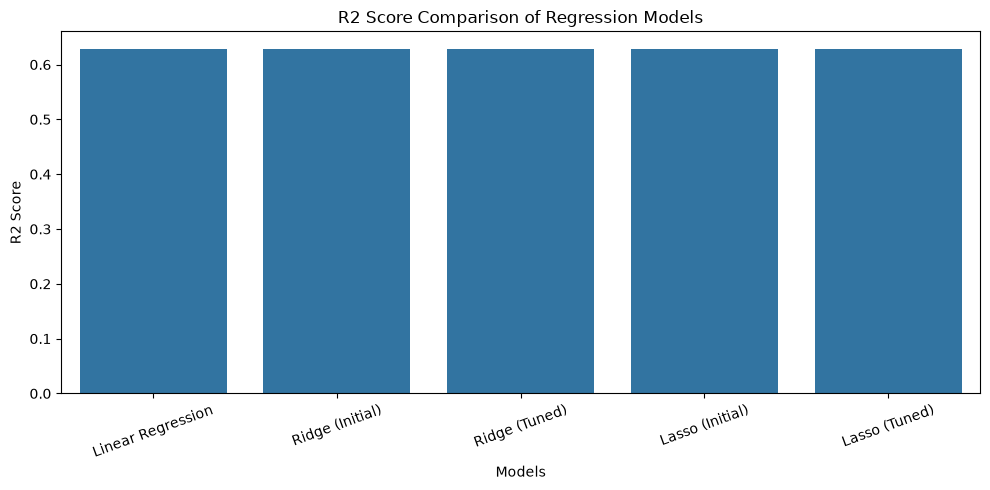

In [216]:
plt.figure(figsize=(10, 5))
sns.barplot(data=final_comparison,x="Model",y="R2 Score")
plt.title("R2 Score Comparison of Regression Models")
plt.xlabel("Models")
plt.ylabel("R2 Score")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [217]:
if ridge_tuned_rmse <= lasso_tuned_rmse:
    best_predictions = y_pred_ridge_tuned
    best_model_name = "Tuned Ridge Regression"
else:
    best_predictions = y_pred_lasso_tuned
    best_model_name = "Tuned Lasso Regression"

print("Selected Model:", best_model_name)

Selected Model: Tuned Lasso Regression


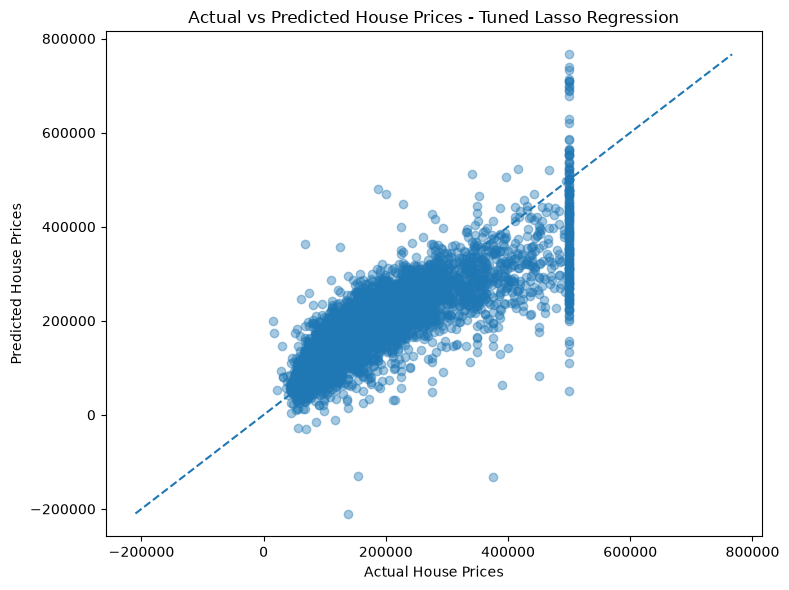

In [218]:
plt.figure(figsize=(8, 6))
plt.scatter(y_test,best_predictions,alpha=0.4)
low = min(y_test.min(), best_predictions.min())
high = max(y_test.max(), best_predictions.max())
plt.plot([low, high],[low, high],linestyle="--")

plt.title(f"Actual vs Predicted House Prices - {best_model_name}")
plt.xlabel("Actual House Prices")
plt.ylabel("Predicted House Prices")
plt.tight_layout()
plt.show()

In [219]:
residuals = y_test - best_predictions

print("First 10 Residuals:")
print(residuals.head(10))

First 10 Residuals:
20046    -16799.426169
3024     -74080.648147
15663    253658.846457
20484    -44260.733649
9814      16613.738014
13311     36149.014298
7113     -94063.282189
7668     -72835.318830
18246     91756.693695
5723      26048.983551
Name: median_house_value, dtype: float64


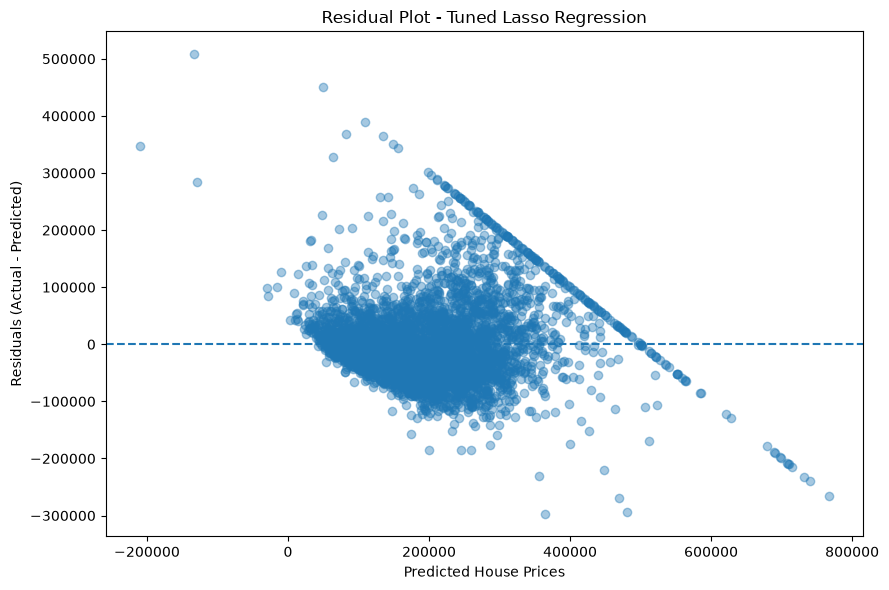

In [220]:
plt.figure(figsize=(9, 6))
plt.scatter(best_predictions,residuals,alpha=0.4)
plt.axhline(y=0,linestyle="--")

plt.title(f"Residual Plot - {best_model_name}")
plt.xlabel("Predicted House Prices")
plt.ylabel("Residuals (Actual - Predicted)")

plt.tight_layout()
plt.show()

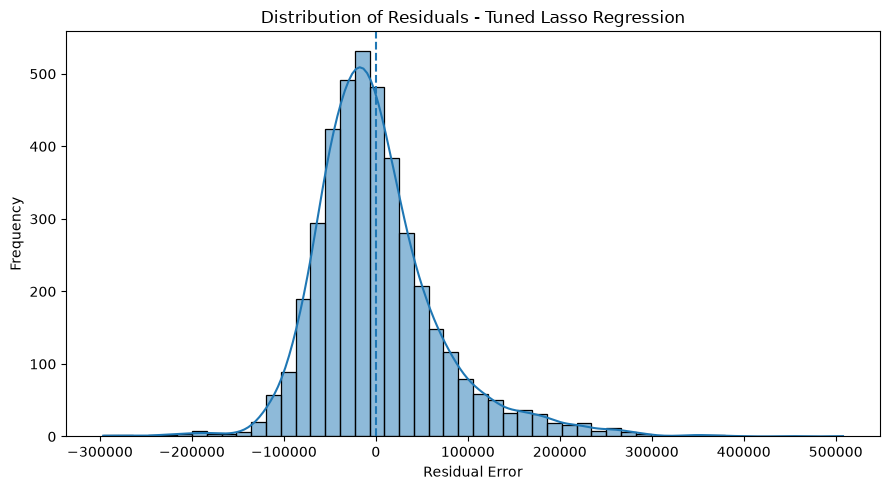

In [221]:
plt.figure(figsize=(9, 5))
sns.histplot(residuals,bins=50,kde=True)
plt.axvline(x=0,linestyle="--")

plt.title(f"Distribution of Residuals - {best_model_name}")
plt.xlabel("Residual Error")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

##  Conclusion

In this project, a regression-based machine learning approach was implemented to predict median house values using the California Housing dataset.

The project included:

- Exploratory Data Analysis (EDA) to understand the dataset and identify missing values.
- Data preprocessing using median imputation, feature scaling, and one-hot encoding.
- Feature engineering using interaction features.
- Multicollinearity analysis using Variance Inflation Factor (VIF).
- Implementation and comparison of Linear Regression, Ridge Regression, and Lasso Regression.
- Hyperparameter optimization using GridSearchCV with 5-fold cross-validation.
- Model evaluation using RMSE, MAE, and R² score.
- Actual vs Predicted, Residual, and Residual Distribution visualizations.

The final model was selected based on its test RMSE. The evaluation results provide insight into the predictive performance and limitations of linear regression-based models for housing price prediction.